# AI Lab: Phase 1 — Dataset Exploration (MNIST)

Welcome to **AI Lab: Handwritten Digit Recognizer**! This project is a progressive, hands-on learning environment for machine learning and deep learning.

In this first phase, our objective is **dataset exploration and sanity checking**:
- Download and load the standard **MNIST dataset** using `torchvision`.
- Store raw data in `../data/raw/`.
- Analyze dataset splits, dimensions, and color channels.
- Examine class distribution to verify balance.
- Inspect raw pixel intensity ranges and fundamental statistics.
- Visualize individual digits and numeric matrices.

> **Note:** In Phase 1, we do not build models or run training. Sound data exploration is the foundational first step of any successful machine learning project.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision

# Print library versions for reproducibility
print(f"PyTorch Version:     {torch.__version__}")
print(f"Torchvision Version: {torchvision.__version__}")
print(f"NumPy Version:       {np.__version__}")
print(f"Pandas Version:      {pd.__version__}")

PyTorch Version:     2.11.0+cpu
Torchvision Version: 0.26.0+cpu
NumPy Version:       2.1.3
Pandas Version:      2.2.3


## 1. Loading the MNIST Dataset

### What is MNIST?
The **MNIST (Modified National Institute of Standards and Technology)** dataset is the "Hello, World!" of computer vision and pattern recognition. It consists of 70,000 grayscale images of handwritten digits (0 through 9) collected from Census Bureau employees and high school students.

### Why torchvision?
`torchvision` provides standard datasets, pre-built loaders, and transformation pipelines. When `download=True` is specified, `torchvision` automatically downloads the compressed IDX binary files if they are not already present.

### Storage Strategy:
We store the raw download in `../data/raw/` so our original dataset remains untouched and reproducible.

In [2]:
# Define dataset path in data/raw
RAW_DATA_PATH = Path("../backend/data/raw") if Path("../backend/data/raw").exists() else Path("backend/data/raw")
RAW_DATA_PATH.mkdir(parents=True, exist_ok=True)

# Load training dataset (60,000 images)
train_dataset = torchvision.datasets.MNIST(
    root=str(RAW_DATA_PATH),
    train=True,
    download=True
)

# Load test dataset (10,000 images)
test_dataset = torchvision.datasets.MNIST(
    root=str(RAW_DATA_PATH),
    train=False,
    download=True
)

print("MNIST dataset successfully loaded into memory!")

MNIST dataset successfully loaded into memory!


## 2. Dataset Dimensions and Split Sizes

### What are we observing?
We observe the total sample counts across the training and testing splits, along with the 2D spatial dimensions of each image tensor.

### Why this matters in Machine Learning:
1. **Train/Test Separation**: Training on 60,000 samples and evaluating on a completely unseen test set of 10,000 samples prevents data leakage. It allows us to measure **generalization** (how well the model performs on new data) rather than mere **memorization** (overfitting).
2. **Spatial Dimensionality ($28 \times 28$)**: Each image has $28 \times 28 = 784$ total pixels. In standard feedforward artificial neural networks (ANNs), these 784 pixels serve as individual input features. In convolutional neural networks (CNNs), the 2D structure $(1, 28, 28)$ is preserved to exploit local spatial relationships (edges, corners, loops).

In [3]:
num_train = len(train_dataset)
num_test = len(test_dataset)
total_samples = num_train + num_test

train_data = train_dataset.data
train_targets = train_dataset.targets
test_data = test_dataset.data
test_targets = test_dataset.targets

print("=" * 50)
print("DATASET SPLIT & DIMENSIONS SUMMARY")
print("=" * 50)
print(f"Training samples:    {num_train:,}  ({num_train / total_samples * 100:.1f}% of total)")
print(f"Testing samples:     {num_test:,}  ({num_test / total_samples * 100:.1f}% of total)")
print(f"Total samples:       {total_samples:,}")
print(f"Image dimensions:    {train_data.shape[1]} x {train_data.shape[2]} pixels")
print(f"Color channels:      1 (Grayscale)")
print(f"Train tensor shape:  {train_data.shape}  [N, H, W]")
print(f"Test tensor shape:   {test_data.shape}  [N, H, W]")
print("=" * 50)

DATASET SPLIT & DIMENSIONS SUMMARY
Training samples:    60,000  (85.7% of total)
Testing samples:     10,000  (14.3% of total)
Total samples:       70,000
Image dimensions:    28 x 28 pixels
Color channels:      1 (Grayscale)
Train tensor shape:  torch.Size([60000, 28, 28])  [N, H, W]
Test tensor shape:   torch.Size([10000, 28, 28])  [N, H, W]


## 3. Class Labels and Target Encoding

### What are we observing?
We inspect the classes present in MNIST and how labels are stored internally.

### Why this matters in Machine Learning:
1. **Multi-Class Classification**: Since there are 10 distinct outcomes (digits 0 through 9), this is a 10-class multi-class problem (unlike binary classification which only has 2 classes).
2. **Label Representation**: The labels are stored as integers `0` through `9`. During training (in future phases), loss functions like Cross-Entropy (`nn.CrossEntropyLoss`) expect integer class indices, which are internally compared against predicted probabilities.

In [4]:
classes = train_dataset.classes
unique_labels = torch.unique(train_targets).tolist()

print(f"Number of classes: {len(classes)}")
print("Class labels and names:")
for idx, cls_name in enumerate(classes):
    print(f"  Index {idx} -> '{cls_name}'")
print(f"\nUnique label values in target tensor: {unique_labels}")

Number of classes: 10
Class labels and names:
  Index 0 -> '0 - zero'
  Index 1 -> '1 - one'
  Index 2 -> '2 - two'
  Index 3 -> '3 - three'
  Index 4 -> '4 - four'
  Index 5 -> '5 - five'
  Index 6 -> '6 - six'
  Index 7 -> '7 - seven'
  Index 8 -> '8 - eight'
  Index 9 -> '9 - nine'

Unique label values in target tensor: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 4. Class Distribution Analysis

### What are we observing?
We calculate and chart the count and percentage share of each digit (0–9) across both the training set and the test set.

### Why this matters in Machine Learning:
1. **Class Balance**: If one digit appeared 90% of the time, a naive model could achieve 90% accuracy simply by guessing that majority class every time without learning anything useful. Checking class distribution confirms that all digits are approximately equally represented (~9% to ~11% each).
2. **Metric Reliability**: Because the classes are well-balanced, standard classification accuracy is a reliable primary metric for benchmarking performance.

Class Distribution Table:
 Digit Class Name  Train Count  Train Share (%)  Test Count  Test Share (%)
     0   0 - zero         5923             9.87         980            9.80
     1    1 - one         6742            11.24        1135           11.35
     2    2 - two         5958             9.93        1032           10.32
     3  3 - three         6131            10.22        1010           10.10
     4   4 - four         5842             9.74         982            9.82
     5   5 - five         5421             9.04         892            8.92
     6    6 - six         5918             9.86         958            9.58
     7  7 - seven         6265            10.44        1028           10.28
     8  8 - eight         5851             9.75         974            9.74
     9   9 - nine         5949             9.92        1009           10.09


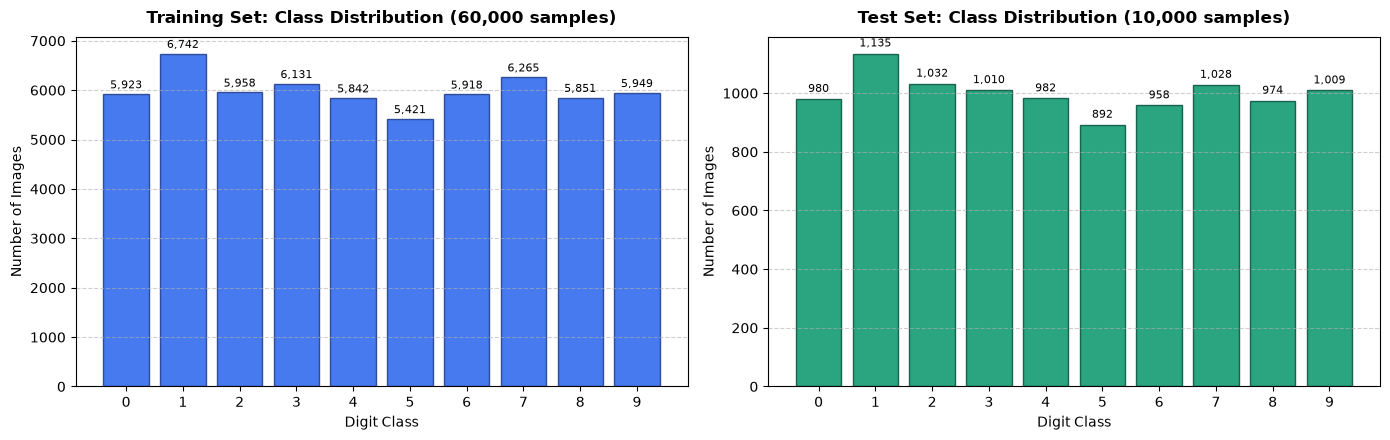

In [5]:
train_counts = pd.Series(train_targets.numpy()).value_counts().sort_index()
test_counts = pd.Series(test_targets.numpy()).value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Digit": range(10),
    "Class Name": [classes[i] for i in range(10)],
    "Train Count": train_counts.values,
    "Train Share (%)": (train_counts.values / num_train * 100).round(2),
    "Test Count": test_counts.values,
    "Test Share (%)": (test_counts.values / num_test * 100).round(2)
})

print("Class Distribution Table:")
print(distribution_df.to_string(index=False))

# Visualize Class Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.bar(train_counts.index, train_counts.values, color="#2563eb", edgecolor="#1e3a8a", alpha=0.85)
ax1.set_title("Training Set: Class Distribution (60,000 samples)", fontsize=12, fontweight="bold", pad=10)
ax1.set_xlabel("Digit Class", fontsize=10)
ax1.set_ylabel("Number of Images", fontsize=10)
ax1.set_xticks(range(10))
ax1.grid(axis="y", linestyle="--", alpha=0.6)
for x, y in zip(train_counts.index, train_counts.values):
    ax1.text(x, y + 60, f"{y:,}", ha="center", va="bottom", fontsize=8)

ax2.bar(test_counts.index, test_counts.values, color="#059669", edgecolor="#064e3b", alpha=0.85)
ax2.set_title("Test Set: Class Distribution (10,000 samples)", fontsize=12, fontweight="bold", pad=10)
ax2.set_xlabel("Digit Class", fontsize=10)
ax2.set_ylabel("Number of Images", fontsize=10)
ax2.set_xticks(range(10))
ax2.grid(axis="y", linestyle="--", alpha=0.6)
for x, y in zip(test_counts.index, test_counts.values):
    ax2.text(x, y + 15, f"{y:,}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

## 5. Pixel Value Range and Basic Dataset Statistics

### What are we observing?
We check the raw minimum, maximum, mean, and standard deviation of pixel values across the training data, as well as the pixel intensity distribution histogram.

### Why this matters in Machine Learning:
1. **Pixel Intensity Scale ($0$ to $255$)**: The raw images use 8-bit unsigned integer values where `0` represents a dark background and `255` represents a full-intensity white pen stroke.
2. **Sparsity**: Notice that a large majority of pixel values are `0` (the background surrounding the handwritten stroke). This sparsity is an important structural feature of handwriting datasets.
3. **Need for Normalization**: Raw inputs ranging from `0` to `255` can cause vanishing or exploding gradients when passed into neural networks with random weight initializations. In future phases, we will normalize pixel values to $[0.0, 1.0]$ or standardize them to mean $\approx 0$ and standard deviation $\approx 1$.

RAW DATASET PIXEL STATISTICS
Data Type:             torch.uint8
Minimum Pixel Value:   0
Maximum Pixel Value:   255
Mean Pixel Intensity:  33.32
Std Dev of Intensity:  78.57
Resolution per image:  28 x 28 = 784 pixels


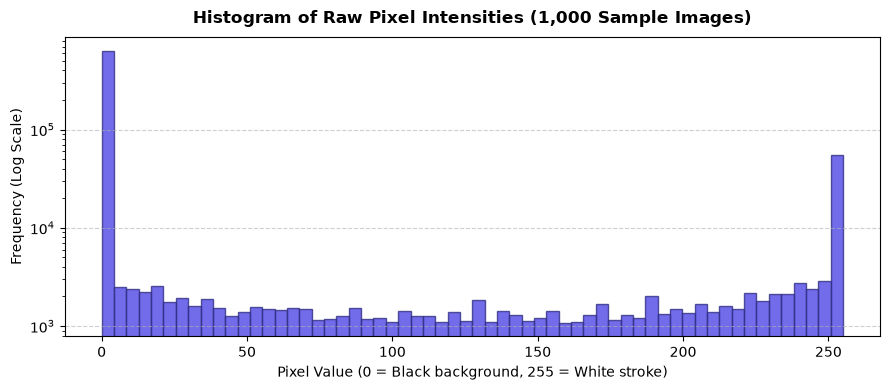

In [6]:
raw_min = train_data.min().item()
raw_max = train_data.max().item()
raw_mean = train_data.float().mean().item()
raw_std = train_data.float().std().item()

print("=" * 50)
print("RAW DATASET PIXEL STATISTICS")
print("=" * 50)
print(f"Data Type:             {train_data.dtype}")
print(f"Minimum Pixel Value:   {raw_min}")
print(f"Maximum Pixel Value:   {raw_max}")
print(f"Mean Pixel Intensity:  {raw_mean:.2f}")
print(f"Std Dev of Intensity:  {raw_std:.2f}")
print(f"Resolution per image:  28 x 28 = {28 * 28} pixels")
print("=" * 50)

# Pixel intensity distribution histogram (sampled from 1,000 images)
sample_pixels = train_data[:1000].flatten().float().numpy()

plt.figure(figsize=(9, 4))
plt.hist(sample_pixels, bins=60, color="#4f46e5", edgecolor="#312e81", alpha=0.8)
plt.title("Histogram of Raw Pixel Intensities (1,000 Sample Images)", fontsize=12, fontweight="bold", pad=10)
plt.xlabel("Pixel Value (0 = Black background, 255 = White stroke)", fontsize=10)
plt.ylabel("Frequency (Log Scale)", fontsize=10)
plt.yscale("log")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## 6. Visualizing Sample Handwritten Digits

### What are we observing?
We render a diverse grid of sample handwritten digits alongside their actual ground-truth labels, followed by a zoomed-in matrix inspection of a single digit.

### Why this matters in Machine Learning:
1. **Intra-class Variation**: Notice how different people write the digit '2', '4', or '7'. Some people cross their 7s, loop their 2s, or slant their numbers. Machine learning models must learn invariant features that capture the digit's essence regardless of individual writing styles.
2. **Connecting Vision to Numbers**: Digital images are just 2D matrices of numbers. By visualizing both the rendered image and its underlying 28x28 numeric values side-by-side, we directly see the input format our mathematical algorithms will process.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


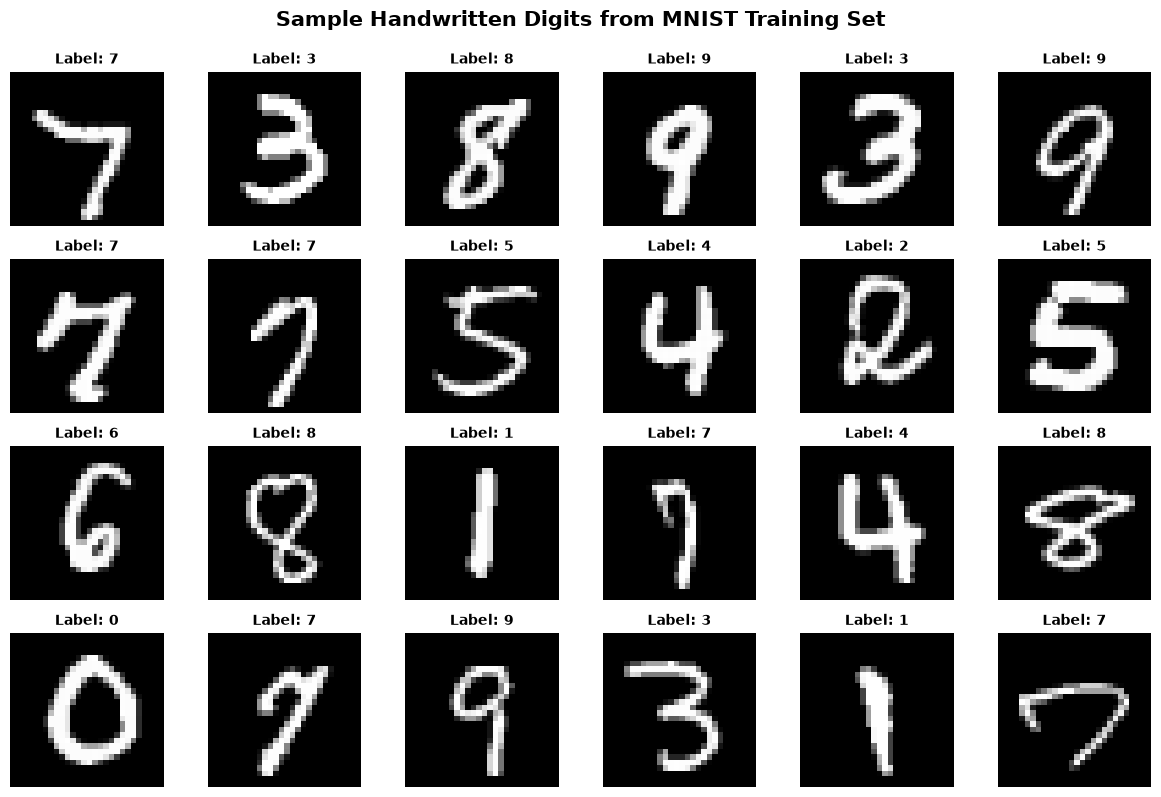

In [7]:
# Display a 4x6 grid of sample digits from the training set
np.random.seed(42)
sample_indices = np.random.choice(len(train_dataset), size=24, replace=False)

fig, axes = plt.subplots(4, 6, figsize=(12, 8))
fig.suptitle("Sample Handwritten Digits from MNIST Training Set", fontsize=15, fontweight="bold", y=0.99)

for idx, ax in zip(sample_indices, axes.flatten()):
    img, label = train_dataset[idx]
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {label}", fontsize=10, fontweight="semibold")
    ax.axis("off")

plt.tight_layout()
plt.show()

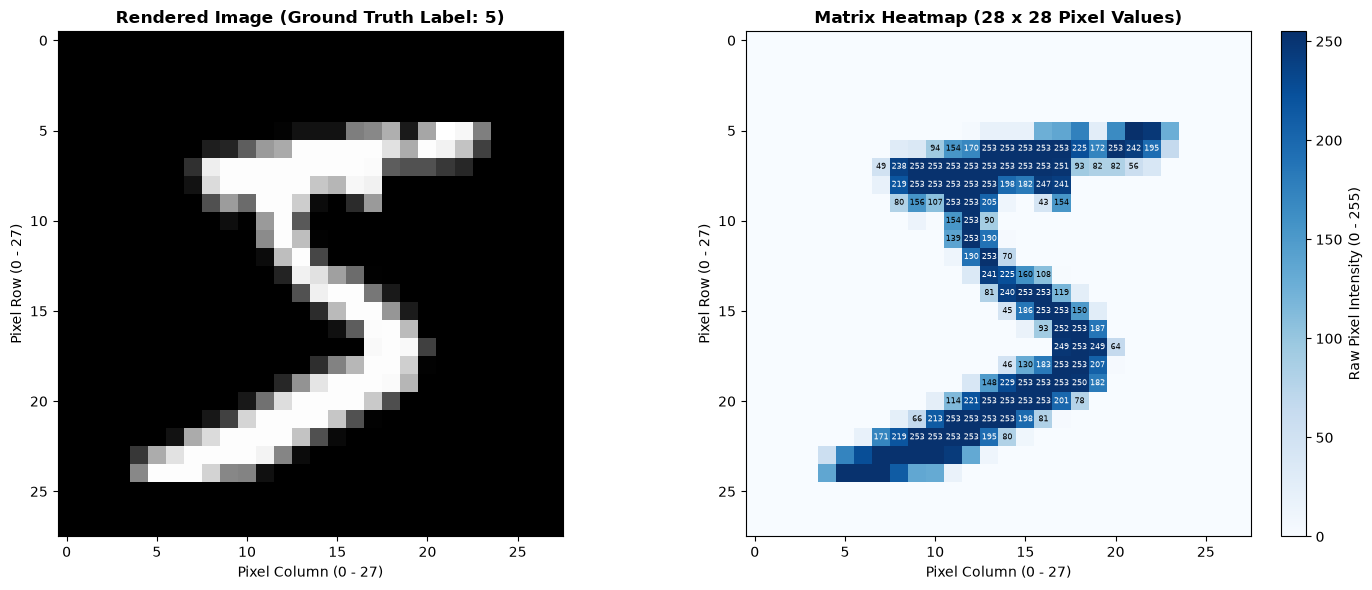

In [8]:
# Detailed view: Image vs. Numeric Matrix Representation for a single sample
sample_idx = 0
sample_img, sample_lbl = train_dataset[sample_idx]
sample_arr = np.array(sample_img)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.4]})

# Visual image display
ax1.imshow(sample_arr, cmap="gray")
ax1.set_title(f"Rendered Image (Ground Truth Label: {sample_lbl})", fontsize=12, fontweight="bold")
ax1.set_xlabel("Pixel Column (0 - 27)")
ax1.set_ylabel("Pixel Row (0 - 27)")

# Heatmap matrix display
im = ax2.imshow(sample_arr, cmap="Blues")
ax2.set_title(f"Matrix Heatmap (28 x 28 Pixel Values)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Pixel Column (0 - 27)")
ax2.set_ylabel("Pixel Row (0 - 27)")
plt.colorbar(im, ax=ax2, label="Raw Pixel Intensity (0 - 255)", fraction=0.046, pad=0.04)

# Overlay numeric intensity values on non-zero pixels in the central region
for r in range(6, 23):
    for c in range(6, 23):
        val = sample_arr[r, c]
        if val > 40:
            color = "white" if val > 160 else "black"
            ax2.text(c, r, str(val), ha="center", va="center", color=color, fontsize=5.5)

plt.tight_layout()
plt.show()

## 7. Summary and Key Findings

### Summary of Dataset Characteristics:
| Property | Value | Description |
| :--- | :--- | :--- |
| **Dataset Name** | MNIST | Modified National Institute of Standards and Technology |
| **Training Samples** | 60,000 | Used exclusively for fitting models |
| **Testing Samples** | 10,000 | Used exclusively for evaluating unseen generalization |
| **Resolution** | 28 $\times$ 28 | 784 total features per image |
| **Channels** | 1 | Grayscale single-channel input |
| **Classes** | 10 | Digits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9 |
| **Class Balance** | ~10% per class | Highly balanced; accuracy is a reliable metric |
| **Raw Pixel Range** | 0 to 255 | 8-bit unsigned integer (sparse background at 0) |

### Key Machine Learning Takeaways:
1. **Uniform Class Distribution**: Since all digits have approximately 6,000 training images each, class imbalance techniques (like oversampling or weighted loss) are unnecessary here.
2. **Data Transformation Required for Phase 2**: For neural network training, we should normalize inputs to $[0, 1]$ via `transforms.ToTensor()` and optionally standardize using MNIST's dataset mean (0.1307) and standard deviation (0.3081).
3. **Zero Model Training**: As requested, this phase establishes data ingestion and statistical verification without training any models.